<a href="https://colab.research.google.com/github/claudio-iturra/doctoral-thesis/blob/main/005-Slab-Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from scipy.io import loadmat
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter
from multitaper import MTSpec
import pickle

In [ ]:
import pickle

with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataA_h.pkl', 'rb') as f:
    dataA = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataB_h.pkl', 'rb') as f:
    dataB = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataC_h.pkl', 'rb') as f:
    dataC = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataD_h.pkl', 'rb') as f:
    dataD = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataE_h.pkl', 'rb') as f:
    dataE = pickle.load(f)

t1 = dataA['time']
t2, t3, t4 = np.array_split(dataE['time'], 3)
t5, t6 = np.array_split(dataC['time'], 2)

del dataA, dataB, dataC, dataD, dataE

In [ ]:
import pickle

with open('/home/cl/Google/@doctorado-sync/database/wind-cs/cs-wind_timeseries.pkl', 'rb') as f:
  cs = pickle.load(f)

In [ ]:
cs

,time,wind_dir_deg,wind_speed_kt,vrb,source_file
0,2004-01-01 00:00:00,20.0,9.0,False,200401.html
1,2004-01-01 01:00:00,20.0,4.0,False,200401.html
2,2004-01-01 02:00:00,20.0,4.0,False,200401.html
3,2004-01-01 03:00:00,20.0,3.0,False,200401.html
4,2004-01-01 04:00:00,90.0,3.0,False,200401.html
...,...,...,...,...,...
26278,2006-12-31 19:00:00,250.0,14.0,False,200612.html
26279,2006-12-31 20:00:00,230.0,13.0,False,200612.html
26280,2006-12-31 21:00:00,230.0,13.0,False,200612.html
26281,2006-12-31 22:00:00,240.0,19.0,False,200612.html


In [ ]:
"""
slab_model.py
=============
Wind-driven near-inertial oscillation model for a shallow shelf site
(Concepcion, Chile shelf; lat = -36.4 deg, water depth ~ 10 m).

Physics
-------
Classic Pollard & Millard (1970) "slab" model treats the mixed layer as a
single well-mixed slab of depth h(t) responding to surface wind stress and
Coriolis rotation, with a linear (Rayleigh) damping representing energy loss
to the stratified interior:

    dUc/dt = -(r_int + i f) * Uc + tau/(rho0 * h)

where Uc = u + i*v is the complex horizontal velocity, f is the Coriolis
parameter, tau = taux + i*tauy is the complex wind stress, rho0 is seawater
density and r_int is an e-folding damping rate.

At a 10 m shelf site, h(t) is frequently a large fraction of (or equal to)
the full water column, so the classic "deep ocean" slab is not really
appropriate on its own: energy loss here is dominated by BOTTOM FRICTION on
the (quasi-)barotropic current, not by radiation into a deep stratified
interior. This module therefore implements the "bottom-friction-limited
slab" (e.g. Shearman, 2005, JPO-style shelf slab models), i.e. treats the
water column of depth h(t) as full-column, and replaces/augments the
constant linear damping with a quadratic bottom-stress term:

    dUc/dt = -i f Uc - r_int*Uc - Cd_bed * |Uc| * Uc / h(t) + tau/(rho0*h(t))

Setting Cd_bed = 0 recovers the classical linear-damped Pollard-Millard slab.
Both are implemented; you choose via the `bottom_drag` argument.

Units: SI throughout (m, s, kg, m/s, Pa).
"""

import numpy as np
from scipy.interpolate import interp1d

# ---------------------------------------------------------------- constants
OMEGA   = 7.292115e-5   # Earth's rotation rate [rad/s]
RHO_AIR = 1.225          # air density [kg/m3]
RHO_SEA = 1025.0         # seawater density [kg/m3]


def coriolis_parameter(lat_deg):
    """Coriolis parameter f [rad/s]. Negative in the Southern Hemisphere."""
    return 2.0 * OMEGA * np.sin(np.deg2rad(lat_deg))


def drag_coefficient_large_pond(wind_speed):
    """
    Sea-surface drag coefficient Cd (dimensionless), Large & Pond (1981),
    valid for 4 <= |W10| <= 25 m/s (extrapolated smoothly outside that range
    here so the function never blows up for calm/storm hourly data).
    """
    w = np.asarray(wind_speed, dtype=float)
    cd = np.where(w < 11.0, 1.2e-3, (0.49 + 0.065 * w) * 1e-3)
    cd = np.clip(cd, 1.0e-3, 2.5e-3)
    return cd


def wind_stress(u10, v10):
    """
    Bulk aerodynamic wind stress from 10-m wind components.
    Returns (taux, tauy) in Pa (N/m^2).
    """
    u10 = np.asarray(u10, dtype=float)
    v10 = np.asarray(v10, dtype=float)
    speed = np.sqrt(u10 ** 2 + v10 ** 2)
    cd = drag_coefficient_large_pond(speed)
    taux = RHO_AIR * cd * speed * u10
    tauy = RHO_AIR * cd * speed * v10
    return taux, tauy


def run_slab_model(t_sec, taux, tauy, h, lat_deg,
                    r_int_days=4.0, Cd_bed=2.5e-3, bottom_drag='quadratic',
                    substeps_per_dt=4, Uc0=0.0 + 0.0j):
    """
    Integrate the (extended) slab model with 4th-order Runge-Kutta.

    Parameters
    ----------
    t_sec : 1-D array, seconds since t0 (monotonic, typically hourly => 3600 spacing)
    taux, tauy : wind stress components [Pa], same length as t_sec
    h : mixed-layer / water-column depth [m], same length as t_sec (can vary in time)
    lat_deg : station latitude [deg, negative = S]
    r_int_days : e-folding damping timescale [days] for the *linear* interior
                 damping term (radiation / dissipation not associated with
                 the bed). Use a long value (e.g. 4-10 d) when bottom_drag is
                 active, since the quadratic term supplies most of the
                 physical damping on a shallow shelf.
    Cd_bed : quadratic bottom drag coefficient (dimensionless), only used if
             bottom_drag='quadratic'. Typical shelf value 2-3e-3.
    bottom_drag : 'quadratic' (Cd_bed*|Uc|*Uc/h), 'linear' (treats Cd_bed as
                  a linear bed friction velocity scale [m/s] instead), or
                  'none' (classic constant-r Pollard-Millard slab).
    substeps_per_dt : number of RK4 substeps per input time interval, for
                      numerical accuracy of the nonlinear bottom-drag term.
    Uc0 : initial complex velocity [m/s]

    Returns
    -------
    Uc : complex ndarray, same length as t_sec -- simulated slab velocity u+iv [m/s]
    """
    t_sec = np.asarray(t_sec, dtype=float)
    n = len(t_sec)
    f = coriolis_parameter(lat_deg)
    r_int = 1.0 / (r_int_days * 86400.0)

    taux_i = interp1d(t_sec, taux, kind='linear', fill_value='extrapolate')
    tauy_i = interp1d(t_sec, tauy, kind='linear', fill_value='extrapolate')
    h_i = interp1d(t_sec, h, kind='linear', fill_value='extrapolate')

    def rhs(tt, Uc):
        hh = float(h_i(tt))
        F = (taux_i(tt) + 1j * tauy_i(tt)) / (RHO_SEA * hh)
        damping = -(r_int + 1j * f) * Uc
        if bottom_drag == 'quadratic':
            damping = damping - Cd_bed * np.abs(Uc) * Uc / hh
        elif bottom_drag == 'linear':
            damping = damping - Cd_bed * Uc / hh   # here Cd_bed acts as [m/s]
        elif bottom_drag == 'none':
            pass
        else:
            raise ValueError("bottom_drag must be 'quadratic', 'linear' or 'none'")
        return damping + F

    Uc = np.zeros(n, dtype=complex)
    Uc[0] = Uc0
    for k in range(n - 1):
        dt_full = t_sec[k + 1] - t_sec[k]
        dt = dt_full / substeps_per_dt
        y = Uc[k]
        tt = t_sec[k]
        for _ in range(substeps_per_dt):
            k1 = rhs(tt, y)
            k2 = rhs(tt + dt / 2, y + dt / 2 * k1)
            k3 = rhs(tt + dt / 2, y + dt / 2 * k2)
            k4 = rhs(tt + dt, y + dt * k3)
            y = y + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
            tt += dt
        Uc[k + 1] = y
    return Uc


def rotary_spectrum(Uc, dt_sec):
    """
    Rotary (clockwise / counter-clockwise) power spectrum of a complex time
    series Uc = u + i*v, following Gonella (1972).

    Returns
    -------
    freq_cph : ndarray, cycles-per-hour, ascending from most-negative (CW)
               to most-positive (CCW) frequency (0 excluded/centered)
    psd : ndarray, power spectral density (same length as freq_cph)
    """
    n = len(Uc)
    Uc = Uc - np.mean(Uc)
    window = np.hanning(n)
    Uc_w = Uc * window
    # normalization for windowed periodogram
    U_hat = np.fft.fftshift(np.fft.fft(Uc_w))
    freq = np.fft.fftshift(np.fft.fftfreq(n, d=dt_sec))  # cycles/second
    freq_cph = freq * 3600.0
    psd = (np.abs(U_hat) ** 2) / (n * np.sum(window ** 2) / n) / n
    return freq_cph, psd

In [ ]:
#

In [ ]:
import pickle

with open('/home/cl/Google/@doctorado-sync/database/wind-cs/cs-wind_timeseries.pkl', 'rb') as f:
  cs = pickle.load(f)

In [ ]:
import numpy as np
theta = np.deg2rad(cs['wind_dir_deg'].astype(float))
# Convert speed from knots to m/s
W = cs['wind_speed_kt'].astype(float) * 0.514444
# Meteorological convention (FROM): minus signs
cs['u'] = -W * np.sin(theta)   # +u is toward east
cs['v'] = -W * np.cos(theta)   # +v is toward north
cs['speed_ms'] = cs['wind_speed_kt'].astype(float) * 0.514444
del W, theta
cs

,time,wind_dir_deg,wind_speed_kt,vrb,source_file,u,v,speed_ms
0,2004-01-01 00:00:00,20.0,9.0,False,200401.html,-1.583552,-4.350773e+00,4.629996
1,2004-01-01 01:00:00,20.0,4.0,False,200401.html,-0.703801,-1.933677e+00,2.057776
2,2004-01-01 02:00:00,20.0,4.0,False,200401.html,-0.703801,-1.933677e+00,2.057776
3,2004-01-01 03:00:00,20.0,3.0,False,200401.html,-0.527851,-1.450258e+00,1.543332
4,2004-01-01 04:00:00,90.0,3.0,False,200401.html,-1.543332,-9.450183e-17,1.543332
...,...,...,...,...,...,...,...,...
26278,2006-12-31 19:00:00,250.0,14.0,False,200612.html,6.767869,2.463303e+00,7.202216
26279,2006-12-31 20:00:00,230.0,13.0,False,200612.html,5.123131,4.298817e+00,6.687772
26280,2006-12-31 21:00:00,230.0,13.0,False,200612.html,5.123131,4.298817e+00,6.687772
26281,2006-12-31 22:00:00,240.0,19.0,False,200612.html,8.464910,4.887218e+00,9.774436


In [ ]:
cs = cs.set_index('time')
cs = cs[['u', 'v']]
# Reindex to a complete hourly range to fill missing timestamps with NaNs
full_hourly_index = pd.date_range(start=cs.index.min(), end=cs.index.max(), freq='h')
cs = cs.reindex(full_hourly_index)
# Interpolate NaN values
cs = cs.interpolate(method='linear')

In [ ]:
cs

,u,v
2004-01-01 00:00:00,-1.583552,-4.350773e+00
2004-01-01 01:00:00,-0.703801,-1.933677e+00
2004-01-01 02:00:00,-0.703801,-1.933677e+00
2004-01-01 03:00:00,-0.527851,-1.450258e+00
2004-01-01 04:00:00,-1.543332,-9.450183e-17
...,...,...
2006-12-31 19:00:00,6.767869,2.463303e+00
2006-12-31 20:00:00,5.123131,4.298817e+00
2006-12-31 21:00:00,5.123131,4.298817e+00
2006-12-31 22:00:00,8.464910,4.887218e+00


In [ ]:
cs_sliced = cs.loc['2004-12-30 00:00:00':'2006-12-30 00:00:00']
cs_sliced

,u,v
2004-12-30 00:00:00,3.383935,1.231651
2004-12-30 01:00:00,1.576348,1.322713
2004-12-30 02:00:00,0.771666,1.336565
2004-12-30 03:00:00,0.089332,0.506628
2004-12-30 04:00:00,-0.000000,-0.000000
...,...,...
2006-12-29 20:00:00,6.699478,5.621530
2006-12-29 21:00:00,8.464910,4.887218
2006-12-29 22:00:00,7.093565,5.952208
2006-12-29 23:00:00,7.093565,5.952208


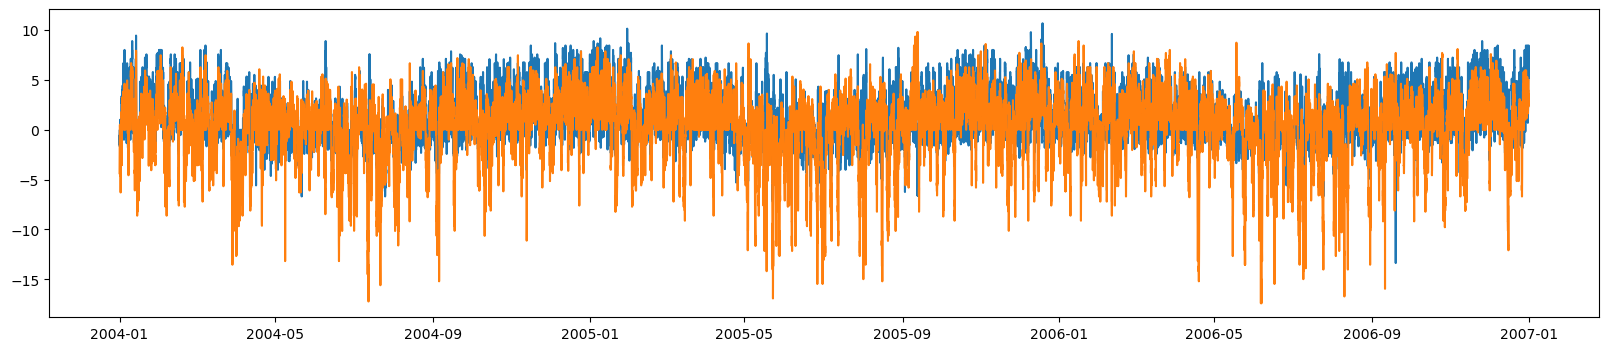

In [ ]:
plt.figure(figsize=(20, 4))
plt.plot(cs['u'])
plt.plot(cs['v'])

In [ ]:
import xarray as xr

# Load the NetCDF file
ds = xr.open_dataset('/home/cl/Google/@doctorado-sync/database/mld-l1/mld.nc')

In [ ]:
target_lon = -73.1224
target_lat = -36.4075

ds_closest_point = (
    ds
    .sel(
        longitude=target_lon,
        latitude=target_lat,
        method='nearest'
    )
    .sel(
        time=slice('2004-12-30 00:00:00', '2006-12-30 00:00:00')
    )
    .resample(time='1h')
    .interpolate('linear')
)

In [ ]:
ds_closest_point['time']

<xarray.DataArray 'time' (time: 17521)> Size: 140kB
array(['2004-12-30T00:00:00.000000000', '2004-12-30T01:00:00.000000000',
       '2004-12-30T02:00:00.000000000', ..., '2006-12-29T22:00:00.000000000',
       '2006-12-29T23:00:00.000000000', '2006-12-30T00:00:00.000000000'],
      shape=(17521,), dtype='datetime64[ns]')
Coordinates:
  * time       (time) datetime64[ns] 140kB 2004-12-30 ... 2006-12-30
    latitude   float32 4B -36.42
    longitude  float32 4B -73.08
Attributes:
    standard_name:  time
    long_name:      Time
    axis:           T

In [ ]:
n = len(cs_sliced['u'])
dt_hours = 1.0
t_sec = np.arange(n) * dt_hours * 3600.0   # seconds since start, required by run_slab_model

LAT = -36.4   # Concepcion shelf

# ---- 2) convert wind to wind stress ----
taux, tauy = wind_stress(cs_sliced['u'].values, cs_sliced['v'].values)

# ---- 3) run the slab model ----
Uc = run_slab_model(
    t_sec, taux, tauy, ds_closest_point['mlotst'].values, LAT,
    r_int_days=10.0,        # weak interior/linear damping
    Cd_bed=2.5e-3,          # quadratic bottom-drag coefficient (shelf physics)
    bottom_drag='quadratic' # 'quadratic' | 'linear' | 'none' (classic Pollard-Millard)
)

u_current = Uc.real   # simulated near-inertial u-current [m/s]
v_current = Uc.imag   # simulated near-inertial v-current [m/s]
speed     = np.abs(Uc)

In [ ]:
import pandas as pd

dates = [
    t1[0], t1[-1],
    t2[0], t2[-1],
    t3[0], t3[-1],
    t4[0], t4[-1],
    t5[0], t5[-1],
    t6[0], t6[-1]
]

# Find the index positions
idx = cs_sliced.index.get_indexer(pd.to_datetime(dates))

print(idx)

[   17   660 10459 11093 11094 11728 11729 12362  4769  5368  5369  5967]


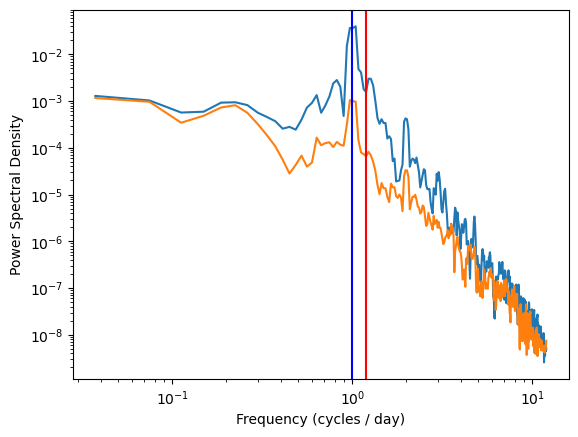

In [ ]:
dt = 1/24
P = 2
cv = u_current[17:660] + 1j * v_current[17:660]
spec = MTSpec(cv - np.mean(cv), nw=2, dt=1/24, iadapt=1, nfft=len(cv))
Sx = np.ravel(spec.spec)
fx = np.ravel(spec.freq)
plt.loglog(fx[fx > 0], Sx[fx > 0])
plt.loglog(-fx[fx < 0], Sx[fx < 0])
plt.xlabel("Frequency (cycles / day)")
plt.ylabel("Power Spectral Density")
plt.axvline(24/24, color = 'blue')
plt.axvline(24/20, color = 'red')

Text(0, 0.5, 'm/s')

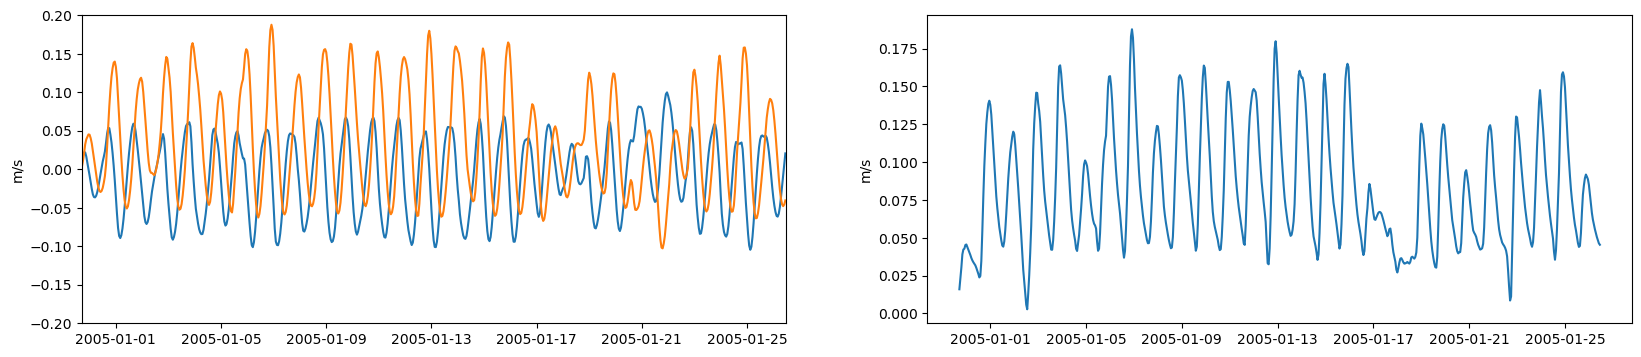

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20,4))
plt.subplot(1,2,1)
plt.plot(cs_sliced.index[17:660], u_current[17:660], label='u_current')
plt.plot(cs_sliced.index[17:660], v_current[17:660], label='v_current')
plt.xlim(t1[0],t1[-1])
plt.ylim([-0.2,0.2])
plt.ylabel('m/s')

plt.subplot(1,2,2)
plt.plot(cs_sliced.index[17:660], np.sqrt(u_current[17:660]**2+v_current[17:660]**2))
plt.ylabel('m/s')


In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
================================================================================
NEAR-INERTIAL OSCILLATION SLAB MODEL
Coastal Ocean of Concepción, Chile | Latitude -36.4° | Depth ~100 m
================================================================================

This script simulates wind-induced near-inertial oscillations (NIO) in the
coastal ocean near Concepción using your hourly wind and mixed layer depth data.

MODEL: Hybrid Slab Model
  Based on Pollard & Millard (1970), with D'Asaro (1985) Ekman subtraction,
  Alford (2001) spectral solution, and Alford (2003) frequency-dependent damping.

  The model solves the damped harmonic oscillator forced by wind stress:

      du/dt =  f*v - r*u + tau_x / (rho_w * H)
      dv/dt = -f*u - r*v + tau_y / (rho_w * H)

  Where:
      f  = 2*Omega*sin(latitude)   [Coriolis parameter, rad/s]
      r  = damping coefficient      [1/s]  (Alford 2003: r = 0.1-0.3 * |f|)
      H  = mixed layer depth        [m]
      tau = wind stress vector      [N/m^2]
      rho_w = seawater density      [kg/m^3]

COASTAL ADAPTATIONS:
  - Bottom friction term added for shallow coastal waters (~100 m)
  - Damping tuned for coastal environment (stronger than open ocean)
  - Rotary spectrum to verify clockwise rotation in Southern Hemisphere

INPUT DATA (from your variables):
  - cs_sliced['u'].values  : zonal wind at 10m [m/s]
  - cs_sliced['v'].values  : meridional wind at 10m [m/s]
  - ds_closest_point['mlotst'].values : mixed layer depth [m]

REFERENCES:
  [1] Pollard, R.T. & Millard, R.C. (1970). Deep Sea Research, 17(5), 813-821.
      doi:10.1016/0011-7471(70)90042-2
  [2] D'Asaro, E.A. (1985). J. Phys. Oceanogr., 15(8), 1043-1059.
      doi:10.1175/1520-0485(1985)015<1043:TEIOWA>2.0.CO;2
  [3] Alford, M.H. (2001). J. Phys. Oceanogr., 31(8), 2357-2363.
      doi:10.1175/1520-0485(2001)031<2357:IGMATH>2.0.CO;2
  [4] Alford, M.H. (2003). Geophys. Res. Lett., 30(8), 1424.
      doi:10.1029/2002GL016614
  [5] Alford, M.H. (2020). J. Phys. Oceanogr., 50(11), 3141-3156.
      doi:10.1175/JPO-D-20-0105.1
  [6] Weller, R.A. (1982). J. Phys. Oceanogr., 12(10), 1128-1141.
      doi:10.1175/1520-0485(1982)012<1128:TRONIM>2.0.CO;2
  [7] Large, W.G. & Pond, S. (1981). J. Phys. Oceanogr., 11(3), 324-336.
      doi:10.1175/1520-0485(1981)011<0324:OOTSWD>2.0.CO;2
  [8] Plueddemann, A.J. & Farrar, J.T. (2006). J. Phys. Oceanogr., 36(8), 1556-1572.
      doi:10.1175/JPO2919.1
================================================================================
"""

import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.signal import welch, butter, filtfilt
from scipy.fft import fft, fftfreq
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

# =============================================================================
# 1. USER CONFIGURATION - MODIFY THESE FOR YOUR DATA
# =============================================================================

LATITUDE = -36.4          # Concepción, Chile [degrees]
BATHYMETRY_DEPTH = 100.0  # Coastal ocean depth [m]
RHO_W = 1025.0            # Seawater density [kg/m^3]
RHO_AIR = 1.225           # Air density at sea level [kg/m^3]
OMEGA = 7.2921159e-5      # Earth's rotation rate [rad/s]

# Damping parameterization (Alford 2003; Park et al. 2009)
# For coastal waters, damping is stronger than open ocean
# Open ocean: r^-1 ~ 5-7 days | Coastal: r^-1 ~ 2-4 days
DAMPING_DAYS = 3.0        # Inverse damping time scale [days]

# Bottom friction coefficient for coastal shallow water
# Only active when H_mld approaches bathymetry
CD_BOTTOM = 0.0025        # Bottom drag coefficient

# Output file
OUTPUT_CSV = "nio_concepcion_simulation.csv"
OUTPUT_PLOT = "nio_concepcion_results.png"
OUTPUT_SPECTRUM = "nio_concepcion_spectrum.png"

# =============================================================================
# 2. COMPUTED PARAMETERS
# =============================================================================

f = 2 * OMEGA * np.sin(np.radians(LATITUDE))   # Coriolis [rad/s]
r = 1.0 / (DAMPING_DAYS * 24 * 3600)            # Damping [1/s]
inertial_period_hours = 2 * np.pi / np.abs(f) / 3600
inertial_period_days = inertial_period_hours / 24

print("=" * 70)
print("  NEAR-INERTIAL OSCILLATION SLAB MODEL")
print("  Coastal Ocean of Concepción, Chile")
print("=" * 70)
print(f"  Latitude:            {LATITUDE}°")
print(f"  Bathymetry:          {BATHYMETRY_DEPTH} m")
print(f"  Coriolis f:          {f:.6e} rad/s")
print(f"  Inertial period:     {inertial_period_hours:.2f} h ({inertial_period_days:.3f} days)")
print(f"  Inertial frequency:  {np.abs(f)*1e5:.3f} × 10⁻⁵ rad/s")
print(f"  Damping r:           {r:.3e} s⁻¹  (decay: {DAMPING_DAYS} days)")
print(f"  Damping ratio:       {r/np.abs(f):.3f} × |f|  (Alford 2003: 0.1-0.3)")
print("=" * 70)


# =============================================================================
# 3. WIND STRESS (Large & Pond 1981)
# =============================================================================

def compute_wind_stress(u_wind, v_wind, rho_air=RHO_AIR):
    """
    Compute wind stress from 10m wind using Large & Pond (1981) drag coefficient.

    Cd formulation:
        |U| ≤ 11 m/s:   Cd = 1.2 × 10⁻³
        11 < |U| ≤ 19:  Cd = (0.49 + 0.065|U|) × 10⁻³
        |U| > 19 m/s:   Cd = (1.364 + 0.0234|U| - 0.00023158|U|²) × 10⁻³

    Reference: Large & Pond (1981), J. Phys. Oceanogr., 11(3), 324-336.
    """
    u = np.asarray(u_wind, dtype=float)
    v = np.asarray(v_wind, dtype=float)
    U_mag = np.sqrt(u**2 + v**2)

    Cd = np.zeros_like(U_mag)
    Cd[U_mag <= 11] = 1.2e-3
    mask = (U_mag > 11) & (U_mag <= 19)
    Cd[mask] = (0.49 + 0.065 * U_mag[mask]) * 1e-3
    mask = U_mag > 19
    Cd[mask] = (1.364 + 0.0234 * U_mag[mask] - 0.00023158 * U_mag[mask]**2) * 1e-3

    tau_x = rho_air * Cd * U_mag * u
    tau_y = rho_air * Cd * U_mag * v

    return tau_x, tau_y, Cd, U_mag


# =============================================================================
# 4. COASTAL SLAB MODEL WITH BOTTOM FRICTION
# =============================================================================

def slab_model_coastal(t, y, f_param, r_param, tau_x_interp, tau_y_interp,
                       H_interp, rho_w, H_bathy, cd_bottom):
    """
    Coastal slab model ODEs with bottom friction correction.

    du/dt =  f*v - r*u - r_bottom*u + tau_x/(rho_w*H)
    dv/dt = -f*u - r*v - r_bottom*v + tau_y/(rho_w*H)

    Bottom friction is activated when MLD is a significant fraction of water depth,
    representing coastal constraint on inertial motions.

    References:
      - Pollard & Millard (1970): Original slab model
      - Alford (2003): Frequency-dependent damping
      - Plueddemann & Farrar (2006): Model-observation comparison
    """
    u, v = y

    tau_x = tau_x_interp(t)
    tau_y = tau_y_interp(t)
    H = max(H_interp(t), 0.5)  # minimum 0.5m to avoid division by zero

    # Bottom friction: proportional to (H_mld / H_bathy)^2
    # Active when mixed layer approaches bottom
    bottom_factor = min((H / H_bathy)**2, 1.0)
    r_bottom = cd_bottom * bottom_factor * np.abs(f_param)

    # Total damping
    r_total = r_param + r_bottom

    du_dt = f_param * v - r_total * u + tau_x / (rho_w * H)
    dv_dt = -f_param * u - r_total * v + tau_y / (rho_w * H)

    return [du_dt, dv_dt]


# =============================================================================
# 5. BANDPASS FILTER FOR NEAR-INERTIAL BAND
# =============================================================================

def bandpass_filter(data, fs, f_low, f_high, order=4):
    """
    Butterworth bandpass filter for isolating near-inertial band.

    Parameters:
    -----------
    data : array
        Time series to filter
    fs : float
        Sampling frequency [Hz]
    f_low, f_high : float
        Lower and upper cutoff frequencies [Hz]
    order : int
        Filter order

    Returns:
    --------
    filtered : array
        Filtered time series
    """
    nyq = 0.5 * fs
    low = f_low / nyq
    high = f_high / nyq
    b, a = butter(order, [low, high], btype='band')
    filtered = filtfilt(b, a, data)
    return filtered


# =============================================================================
# 6. MAIN SIMULATION FUNCTION
# =============================================================================

def simulate_nio(u_wind, v_wind, H_mld,
                 latitude=LATITUDE,
                 bathy_depth=BATHYMETRY_DEPTH,
                 rho_w=RHO_W,
                 damping_days=DAMPING_DAYS,
                 u0=0.0, v0=0.0,
                 dt_hours=1.0):
    """
    Run the complete NIO simulation with your data.

    Parameters:
    -----------
    u_wind, v_wind : array-like
        Hourly wind velocity components at 10m [m/s]
    H_mld : array-like
        Hourly mixed layer depth [m]
    latitude : float
        Latitude in degrees (negative = Southern Hemisphere)
    bathy_depth : float
        Water depth [m]
    rho_w : float
        Seawater density [kg/m^3]
    damping_days : float
        Inverse damping time scale [days]
    u0, v0 : float
        Initial current conditions [m/s]
    dt_hours : float
        Time step [hours]

    Returns:
    --------
    dict with simulation results and diagnostics
    """

    N = len(u_wind)
    t_hours = np.arange(N) * dt_hours
    t_seconds = t_hours * 3600.0

    # Coriolis and damping
    f_local = 2 * OMEGA * np.sin(np.radians(latitude))
    r_local = 1.0 / (damping_days * 24 * 3600)

    # Wind stress
    tau_x, tau_y, Cd, U_mag = compute_wind_stress(u_wind, v_wind)

    # Interpolators
    tau_x_interp = interp1d(t_seconds, tau_x, kind='linear',
                            fill_value='extrapolate', bounds_error=False)
    tau_y_interp = interp1d(t_seconds, tau_y, kind='linear',
                            fill_value='extrapolate', bounds_error=False)
    H_interp = interp1d(t_seconds, H_mld, kind='linear',
                        fill_value='extrapolate', bounds_error=False)

    # Solve ODE
    print(f"\nSolving slab model for {N} hourly timesteps...")
    sol = solve_ivp(
        slab_model_coastal,
        [t_seconds[0], t_seconds[-1]],
        [u0, v0],
        args=(f_local, r_local, tau_x_interp, tau_y_interp,
              H_interp, rho_w, bathy_depth, CD_BOTTOM),
        t_eval=t_seconds,
        method='RK45',
        max_step=3600.0
    )

    u_nio = sol.y[0, :]
    v_nio = sol.y[1, :]
    speed_nio = np.sqrt(u_nio**2 + v_nio**2)

    # Near-inertial kinetic energy [J/m^3]
    NIKE = 0.5 * rho_w * (u_nio**2 + v_nio**2)

    # Wind work (energy flux) [W/m^2]
    wind_work = tau_x * u_nio + tau_y * v_nio

    # Bandpass filter around inertial frequency (±30%)
    fs = 1.0 / 3600.0  # 1/3600 Hz
    f_inertial = np.abs(f_local)
    f_low = 0.7 * f_inertial
    f_high = 1.3 * f_inertial

    u_nio_band = bandpass_filter(u_nio, fs, f_low, f_high)
    v_nio_band = bandpass_filter(v_nio, fs, f_low, f_high)
    speed_nio_band = np.sqrt(u_nio_band**2 + v_nio_band**2)
    NIKE_band = 0.5 * rho_w * (u_nio_band**2 + v_nio_band**2)

    # Rotary analysis
    w_complex = u_nio + 1j * v_nio
    fft_w = fft(w_complex)
    freq = fftfreq(N, d=dt_hours/24)  # cycles per day

    return {
        't_hours': t_hours,
        't_days': t_hours / 24.0,
        'u_nio': u_nio,
        'v_nio': v_nio,
        'speed_nio': speed_nio,
        'u_nio_band': u_nio_band,
        'v_nio_band': v_nio_band,
        'speed_nio_band': speed_nio_band,
        'NIKE': NIKE,
        'NIKE_band': NIKE_band,
        'wind_work': wind_work,
        'tau_x': tau_x,
        'tau_y': tau_y,
        'Cd': Cd,
        'U_mag': U_mag,
        'f': f_local,
        'r': r_local,
        'inertial_period_hours': 2 * np.pi / np.abs(f_local) / 3600,
        'u_wind': np.asarray(u_wind),
        'v_wind': np.asarray(v_wind),
        'H_mld': np.asarray(H_mld),
        'fft_w': fft_w,
        'freq_cpd': freq
    }


# =============================================================================
# 7. PLOTTING FUNCTIONS
# =============================================================================

def plot_timeseries(results, save_path=None):
    """Generate comprehensive time series plot."""

    t_days = results['t_days']

    fig, axes = plt.subplots(6, 1, figsize=(14, 18), sharex=True)
    fig.suptitle(
        f'Near-Inertial Oscillations | Concepción Coast | Lat {LATITUDE}° | '
        f'T = {results["inertial_period_hours"]:.1f} h | Depth {BATHYMETRY_DEPTH} m',
        fontsize=13, fontweight='bold', y=0.995
    )

    # Panel 1: Wind
    ax = axes[0]
    ax.plot(t_days, results['u_wind'], 'b-', alpha=0.7, lw=0.7, label='U wind')
    ax.plot(t_days, results['v_wind'], 'r-', alpha=0.7, lw=0.7, label='V wind')
    ax.set_ylabel('Wind [m/s]')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title('(a) 10m Wind Velocity', loc='left', fontsize=10)
    ax.grid(True, alpha=0.3)

    # Panel 2: Wind stress
    ax = axes[1]
    ax.plot(t_days, results['tau_x'], 'b-', alpha=0.7, lw=0.7, label=r'$\tau_x$')
    ax.plot(t_days, results['tau_y'], 'r-', alpha=0.7, lw=0.7, label=r'$\tau_y$')
    ax.set_ylabel(r'$\tau$ [N m$^{-2}$]')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title('(b) Wind Stress (Large & Pond 1981)', loc='left', fontsize=10)
    ax.grid(True, alpha=0.3)

    # Panel 3: MLD
    ax = axes[2]
    ax.fill_between(t_days, results['H_mld'], alpha=0.3, color='teal')
    ax.plot(t_days, results['H_mld'], 'teal', lw=1.0)
    ax.axhline(y=BATHYMETRY_DEPTH, color='brown', linestyle='--', lw=1.5,
               label=f'Bathymetry = {BATHYMETRY_DEPTH} m')
    ax.set_ylabel('MLD [m]')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title('(c) Mixed Layer Depth', loc='left', fontsize=10)
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)

    # Panel 4: NIO currents (raw)
    ax = axes[3]
    ax.plot(t_days, results['u_nio'] * 100, 'b-', alpha=0.7, lw=0.7, label='U NIO')
    ax.plot(t_days, results['v_nio'] * 100, 'r-', alpha=0.7, lw=0.7, label='V NIO')
    ax.plot(t_days, results['speed_nio'] * 100, 'k--', alpha=0.4, lw=0.8, label='Speed')
    ax.set_ylabel('Current [cm/s]')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title('(d) Simulated NIO Currents (Full Response)', loc='left', fontsize=10)
    ax.grid(True, alpha=0.3)

    # Panel 5: Bandpass-filtered NIO
    ax = axes[4]
    ax.plot(t_days, results['u_nio_band'] * 100, 'b-', alpha=0.8, lw=0.8, label='U NIO [bandpass]')
    ax.plot(t_days, results['v_nio_band'] * 100, 'r-', alpha=0.8, lw=0.8, label='V NIO [bandpass]')
    ax.plot(t_days, results['speed_nio_band'] * 100, 'k--', alpha=0.5, lw=0.8, label='Speed [bandpass]')
    ax.set_ylabel('Current [cm/s]')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_title(f'(e) Bandpass-filtered NIO [0.7f - 1.3f]', loc='left', fontsize=10)
    ax.grid(True, alpha=0.3)

    # Panel 6: NIKE & Wind Work
    ax = axes[5]
    ax2 = ax.twinx()
    ax.plot(t_days, results['NIKE_band'], 'g-', lw=1.2, label='NIKE [bandpass]')
    ax2.plot(t_days, results['wind_work'], 'orange', lw=0.8, alpha=0.6, label='Wind Work')
    ax.set_ylabel('NIKE [J m$^{-3}$]', color='g')
    ax2.set_ylabel('Wind Work [W m$^{-2}$]', color='orange')
    ax.set_xlabel('Time [days]')
    ax.legend(loc='upper left', fontsize=9)
    ax2.legend(loc='upper right', fontsize=9)
    ax.set_title('(f) Near-Inertial Kinetic Energy & Wind Work', loc='left', fontsize=10)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
        print(f"Time series plot saved: {save_path}")
    plt.show()


def plot_spectrum(results, save_path=None):
    """Generate spectral analysis plot with rotary spectrum."""

    N = len(results['u_nio'])
    fs = 1.0 / 3600.0  # Hz

    # Welch PSD
    nperseg = min(512, N // 2)
    noverlap = nperseg // 2

    freq_w, psd_u = welch(results['u_nio'], fs=fs, nperseg=nperseg,
                           noverlap=noverlap, scaling='density')
    _, psd_v = welch(results['v_nio'], fs=fs, nperseg=nperseg,
                     noverlap=noverlap, scaling='density')

    freq_w_cph = freq_w * 3600  # convert to cycles/hour

    # FFT for rotary
    w_complex = results['u_nio'] + 1j * results['v_nio']
    fft_w = fft(w_complex)
    freq_fft = fftfreq(N, d=1)  # cycles/hour (dt=1h)
    pos_mask = freq_fft > 0

    psd_cw = np.abs(fft_w)**2 / N   # Clockwise (SH inertial)
    psd_ccw = np.abs(np.conj(fft_w))**2 / N  # Counter-clockwise

    f_cph = np.abs(results['f']) / (2 * np.pi) * 3600

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        f'Spectral Analysis | Inertial f = {f_cph:.4f} cph ({1/f_cph:.2f}h period) | '
        f'Clockwise in SH',
        fontsize=13, fontweight='bold'
    )

    # Panel 1: Welch PSD
    ax = axes[0, 0]
    ax.semilogy(freq_w_cph, psd_u, 'b-', alpha=0.7, lw=1.0, label='U')
    ax.semilogy(freq_w_cph, psd_v, 'r-', alpha=0.7, lw=1.0, label='V')
    ax.axvline(x=f_cph, color='green', linestyle='--', lw=2,
               label=f'f = {f_cph:.3f} cph')
    ax.set_xlim([0, 0.5])
    ax.set_xlabel('Frequency [cycles/hour]')
    ax.set_ylabel('PSD [m²/s²/Hz]')
    ax.set_title('(a) Welch Power Spectral Density')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Panel 2: Zoom around inertial frequency
    ax = axes[0, 1]
    ax.semilogy(freq_w_cph, psd_u, 'b-', alpha=0.7, lw=1.2, label='U')
    ax.semilogy(freq_w_cph, psd_v, 'r-', alpha=0.7, lw=1.2, label='V')
    ax.axvline(x=f_cph, color='green', linestyle='--', lw=2.5,
               label=f'Inertial f = {f_cph:.4f} cph')
    ax.set_xlim([f_cph - 0.05, f_cph + 0.05])
    ax.set_xlabel('Frequency [cycles/hour]')
    ax.set_ylabel('PSD [m²/s²/Hz]')
    ax.set_title('(b) Zoom: Inertial Frequency Band')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Panel 3: Rotary spectrum
    ax = axes[1, 0]
    ax.semilogy(freq_fft[pos_mask], psd_cw[pos_mask], 'purple', alpha=0.7,
                lw=1.2, label='Clockwise (CW)')
    ax.semilogy(freq_fft[pos_mask], psd_ccw[pos_mask], 'orange', alpha=0.7,
                lw=1.2, label='Counter-CW (CCW)')
    ax.axvline(x=f_cph, color='green', linestyle='--', lw=2,
               label=f'f = {f_cph:.3f} cph')
    ax.set_xlim([0, 0.5])
    ax.set_xlabel('Frequency [cycles/hour]')
    ax.set_ylabel('Rotary PSD')
    ax.set_title('(c) Rotary Spectrum (CW = inertial in SH)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Panel 4: Hodograph (velocity ellipse)
    ax = axes[1, 1]
    # Use bandpass-filtered data for clean ellipse
    u_bp = results['u_nio_band']
    v_bp = results['v_nio_band']
    # Plot a representative window (e.g., 5 inertial periods)
    n_points = min(int(5 * results['inertial_period_hours']), len(u_bp))
    ax.plot(u_bp[:n_points]*100, v_bp[:n_points]*100, 'b-', lw=1.0, alpha=0.7)
    ax.scatter(u_bp[0]*100, v_bp[0]*100, color='red', s=50, zorder=5, label='Start')
    ax.set_xlabel('U [cm/s]')
    ax.set_ylabel('V [cm/s]')
    ax.set_title(f'(d) Velocity Hodograph (~{5*results["inertial_period_hours"]:.0f}h)')
    ax.set_aspect('equal')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
        print(f"Spectrum plot saved: {save_path}")
    plt.show()




  NEAR-INERTIAL OSCILLATION SLAB MODEL
  Coastal Ocean of Concepción, Chile
  Latitude:            -36.4°
  Bathymetry:          100.0 m
  Coriolis f:          -8.654559e-05 rad/s
  Inertial period:     20.17 h (0.840 days)
  Inertial frequency:  8.655 × 10⁻⁵ rad/s
  Damping r:           3.858e-06 s⁻¹  (decay: 3.0 days)
  Damping ratio:       0.045 × |f|  (Alford 2003: 0.1-0.3)


In [ ]:
# YOUR REAL DATA
u_wind = cs_sliced['u'].values      # hourly zonal wind [m/s]
v_wind = cs_sliced['v'].values      # hourly meridional wind [m/s]
H_mld = ds_closest_point['mlotst'].values  # hourly MLD [m]

In [ ]:
len(H_mld)

17521

In [ ]:
#!/usr/bin/env python3
"""
MINIMAL NIO SLAB MODEL - Ready to run with your data
Concepción Coast | Lat -36.4° | Depth ~100m

Just replace the synthetic data section with your real variables.
"""

import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.signal import welch, butter, filtfilt
from scipy.fft import fft, fftfreq
import matplotlib.pyplot as plt

# =============================================================================
# 1. PARAMETERS (fixed for your location)
# =============================================================================
LATITUDE = -36.4          # degrees
BATHYMETRY = 100.0        # m
RHO_W = 1025.0            # kg/m3
RHO_AIR = 1.225           # kg/m3
OMEGA = 7.2921159e-5      # rad/s
DAMPING_DAYS = 3.0        # decay time

f = 2 * OMEGA * np.sin(np.radians(LATITUDE))   # Coriolis [rad/s]
r = 1.0 / (DAMPING_DAYS * 24 * 3600)            # damping [1/s]

u_wind = cs_sliced['u'].values      # hourly zonal wind [m/s]
v_wind = cs_sliced['v'].values      # hourly meridional wind [m/s]
H_mld = ds_closest_point['mlotst'].values  # hourly MLD [m]

# Make sure all arrays have the same length and are 1D numpy arrays
N = len(u_wind)
t_hours = np.arange(N, dtype=float)
t_seconds = t_hours * 3600.0


# =============================================================================
# 3. WIND STRESS (Large & Pond 1981)
# =============================================================================
U_mag = np.sqrt(u_wind**2 + v_wind**2)
Cd = np.zeros_like(U_mag)
Cd[U_mag <= 11] = 1.2e-3
mask = (U_mag > 11) & (U_mag <= 19)
Cd[mask] = (0.49 + 0.065*U_mag[mask])*1e-3
mask = U_mag > 19
Cd[mask] = (1.364 + 0.0234*U_mag[mask] - 0.00023158*U_mag[mask]**2)*1e-3

tau_x = RHO_AIR * Cd * U_mag * u_wind
tau_y = RHO_AIR * Cd * U_mag * v_wind

# =============================================================================
# 4. SLAB MODEL ODE
# =============================================================================
tau_x_i = interp1d(t_seconds, tau_x, kind='linear', fill_value='extrapolate')
tau_y_i = interp1d(t_seconds, tau_y, kind='linear', fill_value='extrapolate')
H_i = interp1d(t_seconds, H_mld, kind='linear', fill_value='extrapolate')

def slab(t, y):
    u, v = y
    tx, ty = tau_x_i(t), tau_y_i(t)
    H = max(H_i(t), 0.5)
    # bottom friction for coastal ~100m
    r_bot = 0.0025 * min((H/BATHYMETRY)**2, 1.0) * np.abs(f)
    r_tot = r + r_bot
    return [f*v - r_tot*u + tx/(RHO_W*H),
            -f*u - r_tot*v + ty/(RHO_W*H)]

# Solve
sol = solve_ivp(slab, [t_seconds[0], t_seconds[-1]], [0.0, 0.0],
                t_eval=t_seconds, method='RK45', max_step=3600)

u_nio = sol.y[0]
v_nio = sol.y[1]
speed = np.sqrt(u_nio**2 + v_nio**2)



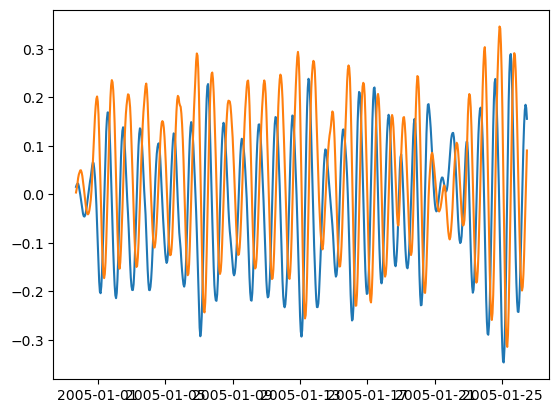

In [ ]:

plt.plot(cs_sliced.index[17:660],u_nio[17:660])
plt.plot(cs_sliced.index[17:660],v_nio[17:660])

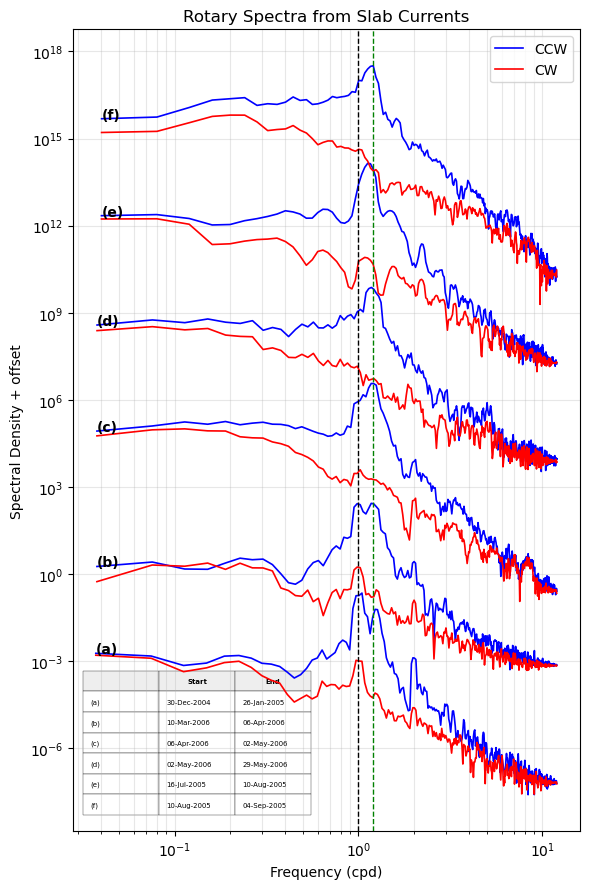

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

time = cs_sliced.index

# Start/end indices
idx = np.array([
    17,    660,
    10459, 11093,
    11094, 11728,
    11729, 12362,
    4769,   5368,
    5369,   5967
])

dt = 1 / 24      # days (hourly sampling)
nw = 2

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

fig, ax = plt.subplots(figsize=(6, 9))

offset_factor = 5000

# Store dates for the table
table_data = []

for i in range(6):

    start = idx[2 * i]
    end   = idx[2 * i + 1]

    cv = u_nio[start:end] + 1j * v_nio[start:end]

    spec = MTSpec(
        cv - np.mean(cv),
        nw=nw,
        dt=dt,
        iadapt=1,
        nfft=len(cv)
    )

    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)

    shifted_Sx = Sx * (offset_factor ** i)

    # Counter-clockwise (positive frequencies)
    ax.loglog(
        fx[fx > 0],
        shifted_Sx[fx > 0],
        'b',
        lw=1.2,
        label='CCW' if i == 0 else ""
    )

    # Clockwise (negative frequencies)
    ax.loglog(
        -fx[fx < 0],
        shifted_Sx[fx < 0],
        'r',
        lw=1.2,
        label='CW' if i == 0 else ""
    )

    # Label each spectrum
    x = shifted_Sx[fx > 0]
    y = fx[fx > 0]
    ax.text(
        y[0],
        x[0],
        labels[i],
        fontsize=10,
        fontweight='bold'
    )

    # Save dates for table
    table_data.append([
        labels[i],
        pd.to_datetime(time[start]).strftime('%d-%b-%Y'),
        pd.to_datetime(time[end]).strftime('%d-%b-%Y')
    ])

# Reference frequencies
ax.axvline(24/24, color='k', ls='--', lw=1)
ax.axvline(24/20, color='g', ls='--', lw=1)

ax.set_xlabel('Frequency (cpd)')
ax.set_ylabel('Spectral Density + offset')
ax.set_title('Rotary Spectra from Slab Currents')

ax.grid(True, which='both', alpha=0.3)
ax.legend(loc='upper right')

# --------------------------------------------------------
# Small table INSIDE the figure (lower-left corner)
# --------------------------------------------------------
table = ax.table(
    cellText=table_data,
    colLabels=['', 'Start', 'End'],
    cellLoc='left',
    colLoc='center',
    bbox=[0.02, 0.02, 0.45, 0.18]   # left, bottom, width, height
)

table.auto_set_font_size(False)
table.set_fontsize(5)

for (row, col), cell in table.get_celld().items():
    cell.set_linewidth(0.25)
    if row == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#eeeeee')

plt.tight_layout()
plt.show()

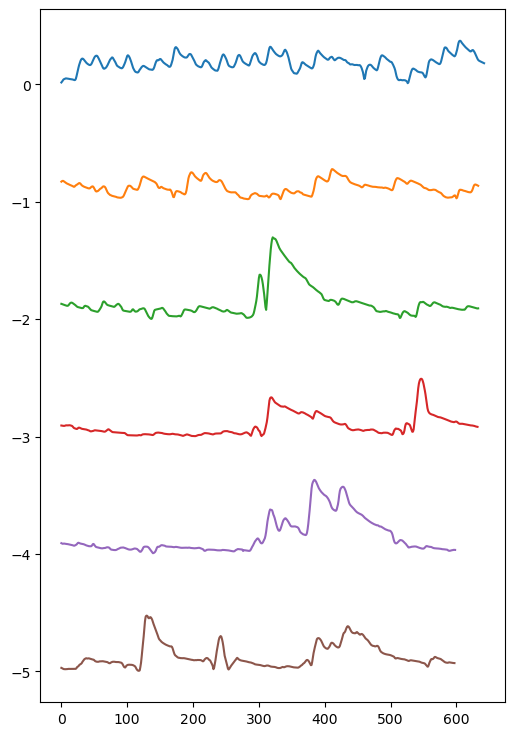

In [ ]:

time = cs_sliced.index

# Start/end indices
idx = np.array([
    17,    660,
    10459, 11093,
    11094, 11728,
    11729, 12362,
    4769,   5368,
    5369,   5967
])

dt = 1 / 24      # days (hourly sampling)
nw = 2

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

fig, ax = plt.subplots(figsize=(6, 9))

offset_factor = 5000

# Store dates for the table
table_data = []

for i in range(6):

    start = idx[2 * i]
    end   = idx[2 * i + 1]

    cv = np.sqrt(u_nio[start:end]**2 + v_nio[start:end]**2)
    plt.plot(cv-1*i)

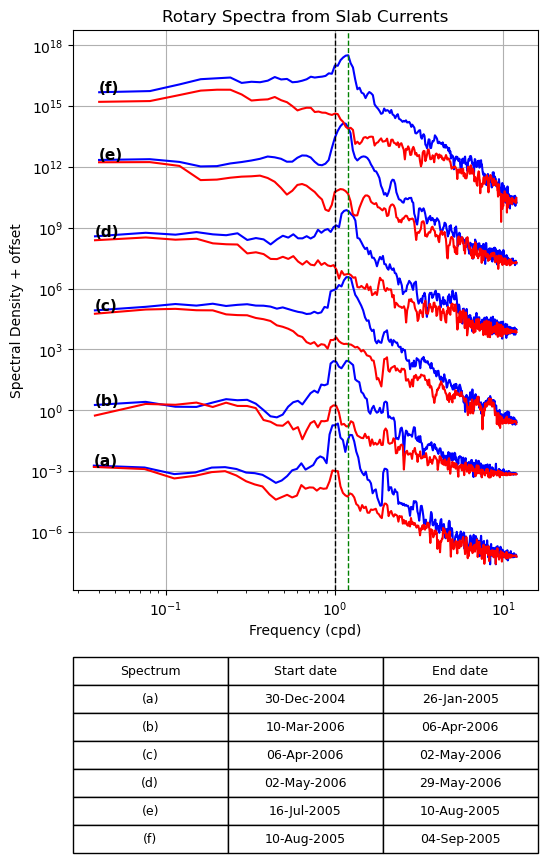

In [ ]:
time = cs_sliced.index

# Start/end indices
idx = np.array([
    17,    660,
    10459, 11093,
    11094, 11728,
    11729, 12362,
    4769,   5368,
    5369,   5967
])

dt = 1 / 24  # days (hourly sampling)
nw = 2

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

fig, ax = plt.subplots(figsize=(6,10))
offset_factor = 5000

# Table data
table_data = []

for i in range(6):

    start = idx[2 * i]
    end   = idx[2 * i + 1]

    cv = u_nio[start:end] + 1j * v_nio[start:end]

    spec = MTSpec(
        cv - np.mean(cv),
        nw=nw,
        dt=dt,
        iadapt=1,
        nfft=len(cv)
    )

    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)
    shifted_Sx = Sx * (offset_factor ** i)

    ax.loglog(fx[fx > 0], shifted_Sx[fx > 0], 'b')
    ax.loglog(-fx[fx < 0], shifted_Sx[fx < 0], 'r')

    x = shifted_Sx[fx > 0]
    y = fx[fx > 0]
    ax.text(y[0], x[0], labels[i], fontsize=11, fontweight='bold')

    # Dates for table
    start_date = pd.to_datetime(time[start]).strftime('%d-%b-%Y')
    end_date   = pd.to_datetime(time[end]).strftime('%d-%b-%Y')

    table_data.append([labels[i], start_date, end_date])

ax.axvline(24/24, color='k', ls='--', lw=1)
ax.axvline(24/20, color='g', ls='--', lw=1)

ax.set_ylabel('Spectral Density + offset')
ax.set_xlabel('Frequency (cpd)')
ax.set_title('Rotary Spectra from Slab Currents')
ax.grid(True)

# Leave room for table
plt.subplots_adjust(bottom=0.32)

# Add table
table = plt.table(
    cellText=table_data,
    colLabels=['Spectrum', 'Start date', 'End date'],
    cellLoc='center',
    colLoc='center',
    bbox=[0.0, -0.47, 1.0, 0.35]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

plt.show()

Text(0.5, 1.0, 'Rotary spectra from slab currents')

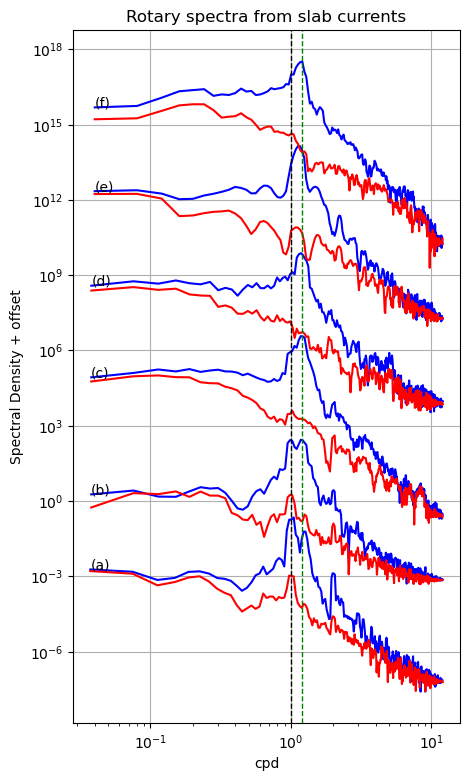

In [ ]:
time = cs_sliced.index

# Start/end indices
idx = np.array([
    17,    660,
    10459, 11093,
    11094, 11728,
    11729, 12362,
    4769,   5368,
    5369,   5967
])

dt = 1 / 24  # days (hourly sampling)
nw = 2

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

plt.figure(figsize=(5,9))
offset_factor = 5000

for i in range(6):

    start = idx[2 * i]
    end   = idx[2 * i + 1]

    cv = u_nio[start:end] + 1j * v_nio[start:end]

    spec = MTSpec(
        cv - np.mean(cv),
        nw=nw,
        dt=dt,
        iadapt=1,
        nfft=len(cv)
    )

    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)
    shifted_Sx = Sx * (offset_factor ** i)
    x =  shifted_Sx[fx > 0]
    y =  fx[fx > 0]

    plt.loglog(fx[fx > 0], shifted_Sx[fx > 0], 'b', label='CCW')

    # Negative rotary spectrum
    plt.loglog(-fx[fx < 0], shifted_Sx[fx < 0], 'r', label='CW')

    plt.text(y[0],x[0],labels[i])

plt.axvline(24/24, color='k', ls='--', lw=1)
plt.axvline(24/20, color='g', ls='--', lw=1)
plt.ylabel('Spectral Density + offset')
plt.xlabel('cpd')
plt.grid()
plt.title('Rotary spectra from slab currents')


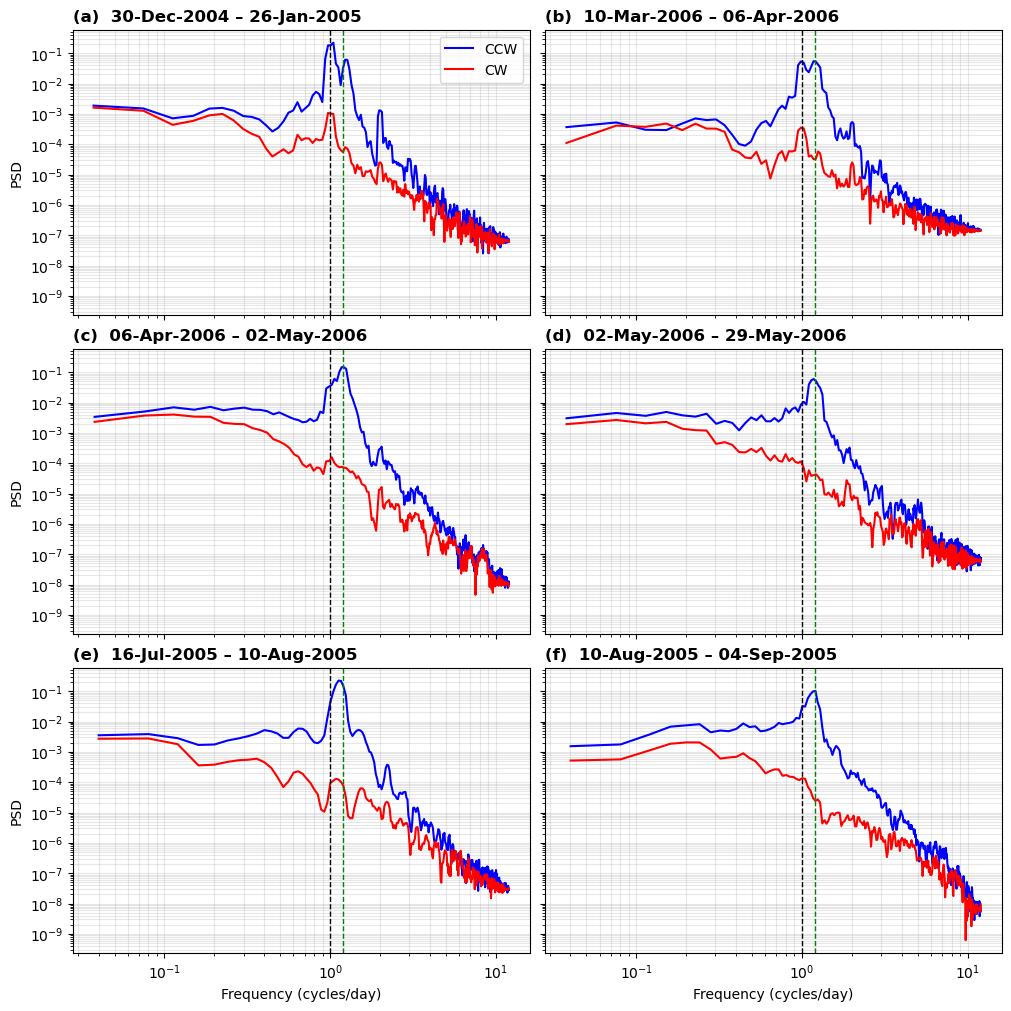

In [ ]:
time = cs_sliced.index

# Start/end indices
idx = np.array([
    17,    660,
    10459, 11093,
    11094, 11728,
    11729, 12362,
    4769,   5368,
    5369,   5967
])

dt = 1 / 24  # days (hourly sampling)
nw = 2

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

fig, axes = plt.subplots(
    3, 2,
    figsize=(10, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

axes = axes.ravel()

for i in range(6):

    start = idx[2 * i]
    end   = idx[2 * i + 1]

    cv = u_nio[start:end] + 1j * v_nio[start:end]

    spec = MTSpec(
        cv - np.mean(cv),
        nw=nw,
        dt=dt,
        iadapt=1,
        nfft=len(cv)
    )

    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)

    ax = axes[i]

    # Positive rotary spectrum
    ax.loglog(fx[fx > 0], Sx[fx > 0], 'b', label='CCW')

    # Negative rotary spectrum
    ax.loglog(-fx[fx < 0], Sx[fx < 0], 'r', label='CW')

    # Diurnal and inertial frequencies
    ax.axvline(24/24, color='k', ls='--', lw=1)
    ax.axvline(24/20, color='g', ls='--', lw=1)

    # Date range
    t0 = time[start].strftime('%d-%b-%Y')
    t1 = time[end].strftime('%d-%b-%Y')

    ax.set_title(
        f'{labels[i]}  {t0} – {t1}',
        loc='left',
        fontweight='bold'
    )

    ax.grid(True, which='both', alpha=0.3)

# Labels
for ax in axes[-2:]:
    ax.set_xlabel('Frequency (cycles/day)')

for ax in axes[::2]:
    ax.set_ylabel('PSD')

axes[0].legend()

plt.show()